## Sourcing et compréhension des données

Dans cette première étape, nous chargeons le dataset **AB_NYC_2019.csv**, qui contient des informations sur les logements Airbnb à New York.


In [1]:
import pandas as pd

newyork = pd.read_csv("Data/AB_NYC_2019.csv")

Nous commençons par explorer la structure du dataset :

- `head()` : afficher les premières lignes pour avoir un aperçu des données.
- `info()` : identifier les colonnes, leurs types et le nombre de valeurs non nulles.
- `describe()` : obtenir des statistiques descriptives sur les variables numériques.

In [2]:
print(newyork.head())

     id                                              name  host_id  \
0  2539                Clean & quiet apt home by the park     2787   
1  2595                             Skylit Midtown Castle     2845   
2  3647               THE VILLAGE OF HARLEM....NEW YORK !     4632   
3  3831                   Cozy Entire Floor of Brownstone     4869   
4  5022  Entire Apt: Spacious Studio/Loft by central park     7192   

     host_name neighbourhood_group neighbourhood  latitude  longitude  \
0         John            Brooklyn    Kensington  40.64749  -73.97237   
1     Jennifer           Manhattan       Midtown  40.75362  -73.98377   
2    Elisabeth           Manhattan        Harlem  40.80902  -73.94190   
3  LisaRoxanne            Brooklyn  Clinton Hill  40.68514  -73.95976   
4        Laura           Manhattan   East Harlem  40.79851  -73.94399   

         room_type  price  minimum_nights  number_of_reviews last_review  \
0     Private room    149               1                  9  20

In [3]:
print(newyork.info())

<class 'pandas.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  str    
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  str    
 4   neighbourhood_group             48895 non-null  str    
 5   neighbourhood                   48895 non-null  str    
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  str    
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     38843 non-n

In [4]:
print(newyork.describe())

                 id       host_id      latitude     longitude         price  \
count  4.889500e+04  4.889500e+04  48895.000000  48895.000000  48895.000000   
mean   1.901714e+07  6.762001e+07     40.728949    -73.952170    152.720687   
std    1.098311e+07  7.861097e+07      0.054530      0.046157    240.154170   
min    2.539000e+03  2.438000e+03     40.499790    -74.244420      0.000000   
25%    9.471945e+06  7.822033e+06     40.690100    -73.983070     69.000000   
50%    1.967728e+07  3.079382e+07     40.723070    -73.955680    106.000000   
75%    2.915218e+07  1.074344e+08     40.763115    -73.936275    175.000000   
max    3.648724e+07  2.743213e+08     40.913060    -73.712990  10000.000000   

       minimum_nights  number_of_reviews  reviews_per_month  \
count    48895.000000       48895.000000       38843.000000   
mean         7.029962          23.274466           1.373221   
std         20.510550          44.550582           1.680442   
min          1.000000           0.00


Ensuite, nous vérifions la présence de valeurs manquantes (`NaN`) en calculant leur nombre et leur pourcentage pour chaque colonne pour mieux comprendre les données, identifier d'éventuels problèmes de qualité et préparer les prochaines étapes de l'analyse.

In [5]:
newyork.isnull().sum()

id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                 10052
calculated_host_listings_count        0
availability_365                      0
dtype: int64

In [6]:
print(newyork.isna().mean() * 100)

id                                 0.000000
name                               0.032723
host_id                            0.000000
host_name                          0.042949
neighbourhood_group                0.000000
neighbourhood                      0.000000
latitude                           0.000000
longitude                          0.000000
room_type                          0.000000
price                              0.000000
minimum_nights                     0.000000
number_of_reviews                  0.000000
last_review                       20.558339
reviews_per_month                 20.558339
calculated_host_listings_count     0.000000
availability_365                   0.000000
dtype: float64


## Nettoyage
Il y a 4 colonnes avec des valeurs manquantes : name, host_name, last_review et reviews_per_month.



- host_name : nous supprimons cette colonne parce que nous avons déjà host_id pour identifier chaque hôte. Le nom n'apporte pas d'information importante pour notre analyse.

In [7]:
newyork = newyork.drop(columns=["host_name"])

- name : nous gardons cette colonne parce que les descriptions des logements pourraient être utiles pour prédire les prix. Nous remplaçons les 16 valeurs manquantes par « Unknown ».

In [8]:
newyork["name"] = newyork["name"].fillna("Unknown")

- last_review : nous gardons cette colonne pour le moment, car la date de la dernière évaluation pourrait nous donner des informations sur l'activité des logements.

- reviews_per_month : nous gardons aussi cette colonne parce qu'elle indique la fréquence moyenne des évaluations et pourrait être liée au prix des logements.

Pour les deux dernières colonnes, nous allons vérifier si les valeurs manquantes correspondent aux logements qui n'ont jamais reçu d'avis. Si c'est le cas, nous remplacerons les NaN de reviews_per_month par 0 et nous garderons les NaN de last_review, car aucune date n'existe.

In [9]:
newyork.loc[newyork["reviews_per_month"].isna(), "number_of_reviews"].value_counts()

number_of_reviews
0    10052
Name: count, dtype: int64

Nous avons remarqué que les valeurs manquantes de `last_review` et `reviews_per_month` semblent correspondre aux logements qui n'ont reçu aucun avis (`number_of_reviews = 0`).

Nous décidons donc de remplacer les NaN de `reviews_per_month` par 0, car ces logements n'ont pas encore reçu d'avis.

Pour `last_review`, nous gardons les NaN, car il n'existe pas de date de dernière évaluation pour ces logements.

In [10]:
newyork["reviews_per_month"] = newyork["reviews_per_month"].fillna(0)

Nous avons vérifié la présence de doublons dans le jeu de données. Aucun doublon n'a été détecté, ni parmi les lignes ni parmi les identifiants (`id`).

In [11]:
print("Duplicate rows:", newyork.duplicated().sum())

Duplicate rows: 0


In [12]:
print("Duplicate IDs:", newyork["id"].duplicated().sum())

Duplicate IDs: 0


Nous poursuivons notre analyse des prix extrêmes ou potentiellement aberrants.

La colonne `price` est déjà de type numérique (`int64`), donc aucune conversion n'est nécessaire.

In [13]:
newyork["price"].dtype

dtype('int64')

Pour identifier les valeurs extrêmes de la colonne price, nous utilisons la méthode describe().

In [14]:
newyork["price"].describe()

count    48895.000000
mean       152.720687
std        240.154170
min          0.000000
25%         69.000000
50%        106.000000
75%        175.000000
max      10000.000000
Name: price, dtype: float64

Nous remarquons que le prix minimum est de 0$  et le maximum de 10 000$. Un prix de 0 $ n'est pas logique pour notre analyse, mais un prix très élevé n'est pas forcément une erreur.



In [15]:
(newyork["price"] == 0).sum()

np.int64(11)

Nous avons trouvé 11 logements avec un prix de 0 $, que nous supprimons car ce prix n'est pas valide pour notre analyse.

In [16]:
newyork = newyork[newyork["price"] > 0].copy()

Pour les prix très élevés et les durées minimales de séjour, nous avons remarqué que certaines valeurs sont inhabituelles, mais pas forcément incorrectes.

Nous allons donc étudier leur distribution avant de décider si nous devons supprimer certains logements.

In [17]:
print(newyork["price"].quantile([0.50, 0.75, 0.90, 0.95, 0.99, 0.995, 1.00]))

0.500      106.0
0.750      175.0
0.900      269.0
0.950      355.0
0.990      799.0
0.995     1000.0
1.000    10000.0
Name: price, dtype: float64


Nous poursuivons notre analyse des prix extrêmes ou potentiellement aberrants. L'étude des percentiles montre que 99 % des logements coûtent 799 \$ ou moins par nuit, et que 99,5 % ne dépassent pas 1 000 \$, tandis que le prix maximum atteint 10 000 \$.

Nous choisissons donc un seuil de 1 000 \$, correspondant au 99,5e percentile, afin d'exclure les prix les plus extrêmes et de concentrer notre analyse sur la grande majorité du marché. Ces valeurs ne sont pas nécessairement erronées, mais elles peuvent fortement influencer les modèles prédictifs.

In [18]:
expensive_listings = newyork[newyork["price"] > 1000]

print("Number of listings:", len(expensive_listings))
print("Percentage of dataset:", round(len(expensive_listings) / len(newyork) * 100, 2), "%")

Number of listings: 239
Percentage of dataset: 0.49 %


In [19]:
newyork = newyork[newyork["price"] <= 1000].copy()

Nous analysons également la distribution de `minimum_nights`, car notre étude porte principalement sur les locations touristiques. Certains logements imposent des séjours minimums extrêmement longs, parfois de plusieurs années, ce qui semble peu cohérent avec ce type de location.

Nous examinons donc les percentiles de cette variable afin de définir un seuil pertinent et d'exclure les logements davantage destinés aux séjours de longue durée.

In [20]:
print(newyork["minimum_nights"].quantile([0.50, 0.75, 0.90, 0.95, 0.99, 1.00]))

0.50       3.0
0.75       5.0
0.90      28.0
0.95      30.0
0.99      40.0
1.00    1250.0
Name: minimum_nights, dtype: float64


In [21]:
for threshold in [30, 40]:
    excluded = (newyork["minimum_nights"] > threshold).sum()
    percentage = excluded / len(newyork) * 100

    print(f"Threshold: {threshold} nights")
    print("Excluded listings:", excluded)
    print("Percentage excluded:", round(percentage, 2), "%")
    print()

Threshold: 30 nights
Excluded listings: 721
Percentage excluded: 1.48 %

Threshold: 40 nights
Excluded listings: 483
Percentage excluded: 0.99 %



L'analyse des percentiles montre que 95 % des logements exigent un séjour minimum de 30 nuits ou moins, contre 99 % pour 40 nuits.

Nous avons comparé ces deux seuils : un maximum de 30 nuits permet d'exclure 721 logements (1,48 %), contre 483 logements (0,99 %) avec un seuil de 40 nuits.

Nous retenons le seuil de 30 nuits, car il correspond davantage à notre objectif d'étudier les locations touristiques de courte ou moyenne durée, tout en conservant 98,52 % des observations.

In [22]:
newyork = newyork[newyork["minimum_nights"] <= 30].copy()

print("Dataset shape:", newyork.shape)

Dataset shape: (47924, 15)


Après le nettoyage et l'application des filtres sur `price` et `minimum_nights`, notre jeu de données contient **47 935 logements et 15 colonnes**.

## Enrichissement

Nous créons une variable `revenu_estime` en multipliant le prix par le nombre moyen d'avis par mois.

Cette variable est un proxy : elle donne une estimation indirecte de l'activité du logement, mais ne représente pas son revenu réel.

In [23]:
newyork["revenu_estime"] = (
    newyork["price"] * newyork["reviews_per_month"]
)

In [24]:
newyork[["price", "reviews_per_month", "revenu_estime"]].head()

,price,reviews_per_month,revenu_estime
0,149,0.21,31.29
1,225,0.38,85.50
2,150,0.00,0.00
3,89,4.64,412.96
4,80,0.10,8.00


### Catégorisation des prix

Nous avons créé la variable `categorie_prix` afin de distinguer trois segments du marché : **Low-cost** (≤ 100 \$), **Standard** (100–500 \$) et **Luxe** (> 500 \$).

Ces seuils s'appuient sur l'analyse des prix selon le type de logement. Les chambres privées et partagées présentent des prix médians de 70 \$ et 45 \$, ce qui justifie un premier seuil à 100 \$ pour identifier les offres les plus abordables.

Les logements entiers présentent un prix médian de 160 \$ et un 95ᵉ percentile de 450 \$. Le seuil de 500 \$ permet ainsi de distinguer les annonces aux prix particulièrement élevés, tandis que la catégorie Standard couvre une large partie du marché.

Cette classification repose uniquement sur le prix et ne garantit pas le niveau réel de confort ou de luxe des logements.

In [25]:
newyork.groupby("room_type")["price"].quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99]
).unstack()


,0.50,0.75,0.90,0.95,0.99
room_type,,,,,
Entire home/apt,160.0,225.0,325.0,427.5,750.00
Private room,70.0,95.0,130.0,175.0,366.68
Shared room,45.0,75.0,110.0,175.0,400.00


In [26]:
import numpy as np


newyork["categorie_prix"] = np.select(
    [
        newyork["price"] <= 100,
        newyork["price"] <= 500
    ],
    [
        "Low-cost",
        "Standard"
    ],
    default="Luxe"
)

In [27]:
newyork["categorie_prix"].value_counts()

categorie_prix
Low-cost    23595
Standard    23530
Luxe          799
Name: count, dtype: int64

## Visualisation & première reco

### Répartition géographique de prix
Nous visualisons la répartition des prix Airbnb à New York selon la localisation des logements.

Chaque point représente un logement et sa couleur indique son prix par nuit. Nous ajoutons les noms des cinq boroughs pour mieux identifier les zones.

L'échelle des couleurs est limitée à 500 \$ pour faciliter la lecture du graphique, mais tous les logements sont représentés, même ceux dont le prix dépasse 500 $.

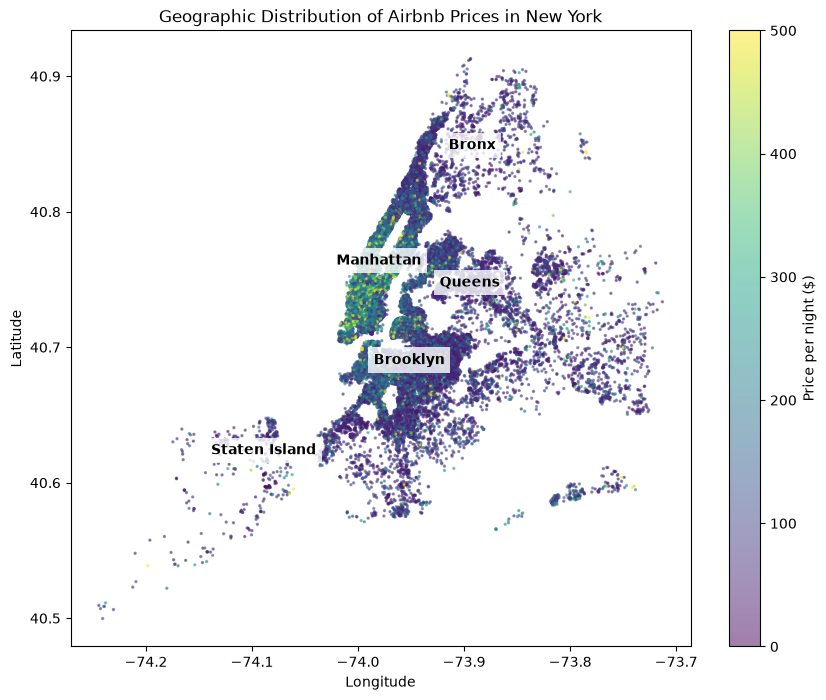

In [28]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 8))

plt.scatter(
    newyork["longitude"],
    newyork["latitude"],
    c=newyork["price"],
    cmap="viridis",
    s=2,
    alpha=0.5,
    vmin=0,
    vmax=500
)

plt.colorbar(label="Price per night ($)")

# Calculate the central position of each borough
centers = newyork.groupby("neighbourhood_group")[
    ["longitude", "latitude"]
].median()

# Add borough names
for borough, position in centers.iterrows():
    plt.text(
        position["longitude"],
        position["latitude"],
        borough,
        fontsize=10,
        fontweight="bold",
        ha="center",
        bbox=dict(facecolor="white", alpha=0.8, edgecolor="none")
    )

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Geographic Distribution of Airbnb Prices in New York")
plt.show()

In [29]:
newyork.groupby("neighbourhood_group")["price"].median().sort_values()

neighbourhood_group
Bronx             65.0
Queens            75.0
Staten Island     75.0
Brooklyn          90.0
Manhattan        149.0
Name: price, dtype: float64

Nous observons une forte concentration de logements à Manhattan et Brooklyn.

Les prix les plus élevés semblent se concentrer à Manhattan, ce qui est confirmé par le prix médian de 150 \$ par nuit.

Le Bronx présente les prix les plus bas, avec une médiane de 65 \$, suivi de Queens et Staten Island (75 \$), puis Brooklyn (90 \$).

Nous remarquons aussi des différences de prix à l'intérieur d'un même borough. La localisation semble donc jouer un rôle important dans le prix des logements.

### Quartiers rentables
Nous cherchons à identifier les quartiers qui présentent le meilleur potentiel économique.

Pour cela, nous comparons la médiane de notre variable revenu_estime par quartier. Nous conservons uniquement les quartiers avec au moins 30 annonces pour éviter de tirer des conclusions à partir de trop peu de logements.

Cet indicateur ne représente pas le revenu réel ni la rentabilité nette des logements.

In [30]:
quartiers = (
    newyork.groupby("neighbourhood")
    .agg(
        revenu_median=("revenu_estime", "median"),
        nombre_logements=("id", "count")
    )
)

quartiers = quartiers[quartiers["nombre_logements"] >= 30]

top_quartiers = quartiers.sort_values(
    "revenu_median", ascending=False
).head(15)

top_quartiers

,revenu_median,nombre_logements
neighbourhood,,
East Elmhurst,243.470,184
Springfield Gardens,209.400,85
Fresh Meadows,191.325,32
South Ozone Park,162.160,40
Arverne,136.500,76
Two Bridges,128.700,71
St. Albans,122.890,76
Mott Haven,118.500,60
Tompkinsville,109.360,42


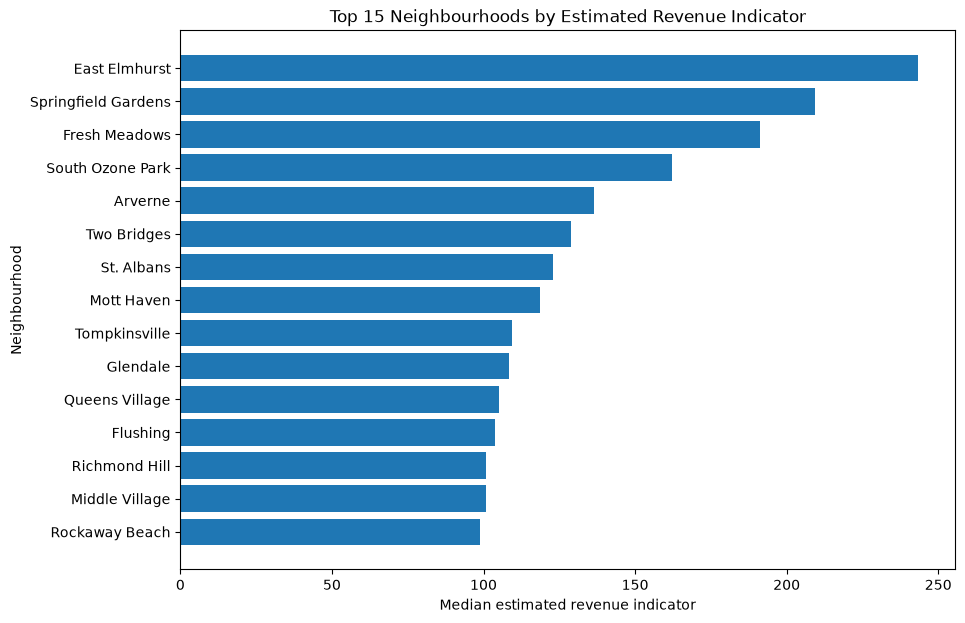

In [31]:
plt.figure(figsize=(10, 7))

plt.barh(
    top_quartiers.index,
    top_quartiers["revenu_median"]
)

plt.gca().invert_yaxis()
plt.xlabel("Median estimated revenue indicator")
plt.ylabel("Neighbourhood")
plt.title("Top 15 Neighbourhoods by Estimated Revenue Indicator")
plt.show()

### Prix selon le type de logement
Nous allons comparer les prix des différents types de logements pour voir si le type de location influence le prix par nuit.

Nous utilisons un boxplot pour visualiser les médianes et la dispersion des prix.

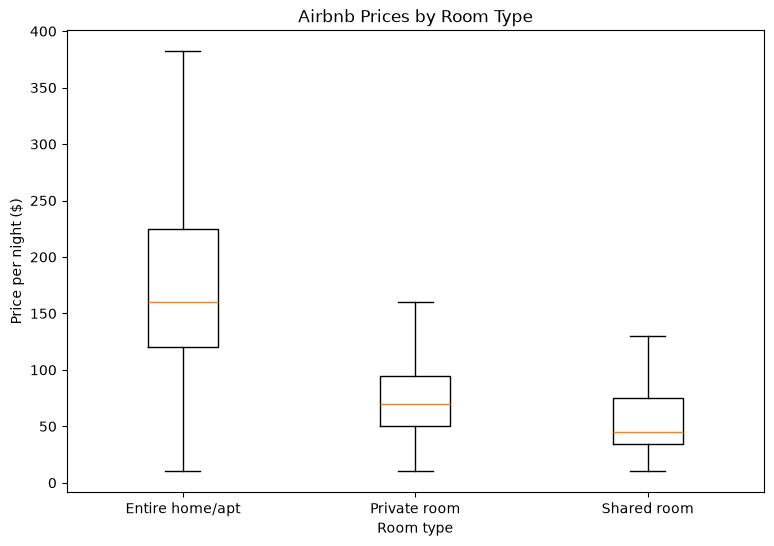

In [32]:


room_types = ["Entire home/apt", "Private room", "Shared room"]

data = [
    newyork.loc[newyork["room_type"] == room, "price"]
    for room in room_types
]

plt.figure(figsize=(9, 6))

plt.boxplot(
    data,
    tick_labels=room_types,
    showfliers=False
)

plt.ylabel("Price per night ($)")
plt.xlabel("Room type")
plt.title("Airbnb Prices by Room Type")
plt.show()

Les logements entiers présentent les prix les plus élevés, avec une médiane de 160 \$ par nuit, suivis des chambres privées (70 \$) et des chambres partagées (45 \$).

Nous observons également une plus grande dispersion des prix pour les logements entiers.

Le type de logement semble donc avoir une influence importante sur le prix par nuit.

### Première recommandation
D'après notre analyse, certains quartiers de Queens, notamment East Elmhurst et Springfield Gardens, semblent intéressants pour un investissement.

Ces quartiers présentent un indicateur de revenu estimé élevé, alors que les prix par nuit à Queens sont généralement plus bas qu'à Manhattan.

Nous recommandons donc d'étudier en priorité ces quartiers pour rechercher des logements qui combinent des prix intéressants et une activité élevée.

Cette première recommandation reste une hypothèse, car nous ne connaissons ni les prix d'achat des biens ni leur taux d'occupation réel.

## Prédire et décider

### Apprentissage supervisé
Nous allons utiliser l'apprentissage supervisé pour prédire le prix par nuit des logements Airbnb.

Notre variable cible (target) est price. Les variables explicatives (features) seront les caractéristiques des logements, comme leur localisation et leur type.

Nous allons séparer les données en deux parties : 80 % pour entraîner le modèle et 20 % pour évaluer ses prédictions sur des données qu'il n'a pas vues.

### Préparer les données
#### Sélection des features

In [33]:
newyork.dtypes

id                                  int64
name                                  str
host_id                             int64
neighbourhood_group                   str
neighbourhood                         str
latitude                          float64
longitude                         float64
room_type                             str
price                               int64
minimum_nights                      int64
number_of_reviews                   int64
last_review                           str
reviews_per_month                 float64
calculated_host_listings_count      int64
availability_365                    int64
revenu_estime                     float64
categorie_prix                        str
dtype: object

Nous sélectionnons les variables qui décrivent les logements, leur localisation et leur activité.

Nous conservons `number_of_reviews` et `reviews_per_month`, car notre objectif est d'analyser les annonces existantes. Nous pourrons ensuite vérifier si ces variables améliorent les prédictions.

Nous excluons `revenu_estime` et `categorie_prix`, car elles sont calculées à partir de `price` et pourraient provoquer une fuite de données (*data leakage*).

In [34]:
features = [
    "neighbourhood_group",
    "neighbourhood",
    "latitude",
    "longitude",
    "room_type",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365"
]

X = newyork[features]
y = newyork["price"]

### Encodage des variables catégorielles

Nous utilisons `pd.get_dummies()` pour transformer les variables catégorielles (`neighbourhood_group`, `neighbourhood` et `room_type`) en colonnes numériques contenant des 0 et des 1.

Cela permet à notre modèle de régression d'utiliser ces variables pour prédire le prix des logements.

In [35]:
X = pd.get_dummies(
    X,
    columns=["neighbourhood_group", "neighbourhood", "room_type"],
    dtype=int
)

In [36]:
X.shape

(47924, 236)

### Séparation des données en train et test

Nous divisons les données en deux ensembles : 80 % pour entraîner notre modèle et 20 % pour évaluer ses performances sur des données qu'il n'a pas utilisées pendant l'entraînement.

Nous utilisons `random_state=42` pour obtenir la même séparation à chaque exécution.

In [37]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (38339, 236)
Test: (9585, 236)


### Baseline 

### Régression linéaire
Nous allons entraîner un premier modèle de régression linéaire pour prédire le prix par nuit des logements.

Ce modèle servira de référence (baseline) pour comparer les performances avec un modèle plus complexe, comme Random Forest.

In [38]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](236,)","[ 6.45,-544.35, -1.9 ,..., 70.81, -22.09, -48.72]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](236,)","['latitude','longitude','minimum_nights',...,'room_type_Entire home/apt', 'room_type_Private room','room_type_Shared room']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-4.043e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,236
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(229)


### Évaluation de la régression linéaire

Nous utilisons notre modèle pour prédire les prix des logements de l'ensemble de test.

Nous comparons ensuite les prix prédits aux prix réels à l'aide de trois métriques : MAE, RMSE et R².

In [39]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_pred = linear_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R²:", round(r2, 3))

MAE: 53.79
RMSE: 92.6
R²: 0.365


La régression linéaire obtient un MAE de 53,79 $, un RMSE de 92,6 \$ et un R² de 0,36 sur le jeu de test.

Le modèle présente donc une erreur absolue moyenne d'environ 54 $ par nuit et explique 36 % de la variabilité des prix.

Ces résultats constituent une première référence pour évaluer les performances des modèles plus complexes.

### Random Forest Regressor

Nous allons entraîner un modèle Random Forest afin de capturer des relations plus complexes entre les caractéristiques des logements et leur prix, puis comparer ses performances à celles de la régression linéaire.

Nous commençons par entraîner un Random Forest avec les paramètres par défaut de scikit-learn : 100 arbres, sans limite de profondeur et avec un minimum d'une observation par feuille.

In [40]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

In [41]:
# Prédictions
y_pred_train = rf_model.predict(X_train)
y_pred_test = rf_model.predict(X_test)

# Évaluation du modèle
for ensemble, valeurs_reelles, predictions in [
    ("Entraînement", y_train, y_pred_train),
    ("Test", y_test, y_pred_test)
]:
    print(ensemble)
    print("MAE :", round(mean_absolute_error(valeurs_reelles, predictions), 2))
    print("RMSE :", round(np.sqrt(mean_squared_error(valeurs_reelles, predictions)), 2))
    print("R² :", round(r2_score(valeurs_reelles, predictions), 3))
    print()

Entraînement
MAE : 18.42
RMSE : 32.76
R² : 0.922

Test
MAE : 48.88
RMSE : 87.63
R² : 0.431



Ce premier modèle obtient un R² de 0,922 en entraînement contre 0,431 en test. Cet écart important révèle un surapprentissage : le modèle s'adapte très bien aux données d'entraînement, mais généralise moins bien aux nouvelles observations.

Pour limiter ce phénomène, nous réalisons plusieurs expériences en modifiant progressivement les hyperparamètres :


In [42]:
rf_depth12 = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

rf_depth12.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",12
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

Nous limitons d'abord la profondeur maximale des arbres à 12, ce qui réduit le R² d'entraînement à 0,658, tandis que le R² de test reste stable à 0,439.

In [43]:
# Prédictions
y_pred_train = rf_depth12.predict(X_train)
y_pred_test = rf_depth12.predict(X_test)

# Évaluation du modèle
for ensemble, valeurs_reelles, predictions in [
    ("Entraînement", y_train, y_pred_train), 
    ("Test", y_test, y_pred_test)
]:
    print(ensemble)
    print("MAE :", round(mean_absolute_error(valeurs_reelles, predictions), 2))
    print("RMSE :", round(np.sqrt(mean_squared_error(valeurs_reelles, predictions)), 2))
    print("R² :", round(r2_score(valeurs_reelles, predictions), 3))
    print()

Entraînement
MAE : 41.06
RMSE : 68.41
R² : 0.658

Test
MAE : 48.07
RMSE : 87.07
R² : 0.439



Nous augmentons ensuite min_samples_leaf à 2, puis à 5, afin d'éviter que les arbres apprennent des particularités trop spécifiques aux données d'entraînement.

In [44]:
rf_leaf2 = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_leaf2.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",12
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

In [45]:
# Prédictions
y_pred_train = rf_leaf2.predict(X_train)
y_pred_test = rf_leaf2.predict(X_test)

# Évaluation du modèle
for ensemble, valeurs_reelles, predictions in [
    ("Entraînement", y_train, y_pred_train),
    ("Test", y_test, y_pred_test)
]:
    print(ensemble)
    print("MAE :", round(mean_absolute_error(valeurs_reelles, predictions), 2))
    print("RMSE :", round(np.sqrt(mean_squared_error(valeurs_reelles, predictions)), 2))
    print("R² :", round(r2_score(valeurs_reelles, predictions), 3))
    print()

Entraînement
MAE : 41.37
RMSE : 70.78
R² : 0.634

Test
MAE : 47.97
RMSE : 86.93
R² : 0.44



In [46]:
rf_leaf5 = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_leaf5.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",12
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

In [47]:
# Prédictions
y_pred_train = rf_leaf5.predict(X_train)
y_pred_test = rf_leaf5.predict(X_test)

# Évaluation du modèle
for ensemble, valeurs_reelles, predictions in [
    ("Entraînement", y_train, y_pred_train),
    ("Test", y_test, y_pred_test)
]:
    print(ensemble)
    print("MAE :", round(mean_absolute_error(valeurs_reelles, predictions), 2))
    print("RMSE :", round(np.sqrt(mean_squared_error(valeurs_reelles, predictions)), 2))
    print("R² :", round(r2_score(valeurs_reelles, predictions), 3))
    print()

Entraînement
MAE : 42.65
RMSE : 75.1
R² : 0.588

Test
MAE : 47.86
RMSE : 86.9
R² : 0.441



Nous conservons `min_samples_leaf=5` car il permet de réduire le surapprentissage tout en maintenant des performances similaires sur les données de test. La validation croisée confirme ensuite que les résultats avec 2 et 5 sont presque identiques.

### Validation croisée

Nous utilisons une validation croisée à 5 plis (*5-fold cross-validation*) sur les données d'entraînement afin de comparer les hyperparamètres du Random Forest sans utiliser les données de test.

Cette méthode permet d'obtenir une estimation plus fiable des performances du modèle.

In [48]:
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestRegressor

rf_cv = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

cv_scores = cross_val_score(
    rf_cv,
    X_train,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error"
)

cv_mae = -cv_scores

print("MAE for each fold:", cv_mae.round(2))
print("Mean MAE:", round(cv_mae.mean(), 2))
print("Standard deviation:", round(cv_mae.std(), 2))

MAE for each fold: [47.86 48.78 48.78 48.42 50.73]
Mean MAE: 48.91
Standard deviation: 0.97


Les résultats sont similaires sur les cinq plis, avec un MAE moyen de 48,91 \$ et un écart-type de 0,97 $. Le modèle présente donc des performances relativement stables selon les différentes divisions des données d'entraînement.

#### Comparaison des valeurs de `max_depth`

Nous comparons différentes profondeurs maximales (`8`, `12` et `16`) à l'aide d'une validation croisée à 5 plis, afin de déterminer leur influence sur les performances du modèle.

In [ ]:

depth_values = [8, 12, 16]

for depth in depth_values:
    rf = RandomForestRegressor(
        n_estimators=100,
        max_depth=depth,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    )

    scores = cross_val_score(
        rf,
        X_train,
        y_train,
        cv=5,
        scoring="neg_mean_absolute_error"
    )

    mae_scores = -scores

    print(
        f"Depth: {depth} | "
        f"Mean MAE: {mae_scores.mean():.2f} | "
        f"Std: {mae_scores.std():.2f}"
    )

Depth: 8 | Mean MAE: 50.26 | Std: 1.01
Depth: 12 | Mean MAE: 48.91 | Std: 0.97
Depth: 16 | Mean MAE: 48.79 | Std: 0.96


Le MAE diminue lorsque la profondeur augmente, mais l'amélioration entre `max_depth=12` et `16` est très faible (0,12 $). Nous conservons donc `max_depth=12`, qui offre un bon compromis entre performance et complexité du modèle.

#### Comparaison des valeurs de `min_samples_leaf`

Nous comparons `min_samples_leaf=2`, `5` et `10` à l'aide d'une validation croisée à 5 plis, afin d'évaluer l'effet de la taille minimale des feuilles sur les performances du modèle.

In [ ]:

leaf_values = [2, 5, 10]

for leaf in leaf_values:
    rf = RandomForestRegressor(
        n_estimators=100,
        max_depth=12,
        min_samples_leaf=leaf,
        random_state=42,
        n_jobs=-1
    )

    scores = cross_val_score(
        rf,
        X_train,
        y_train,
        cv=5,
        scoring="neg_mean_absolute_error"
    )

    mae_scores = -scores

    print(
        f"Min samples leaf: {leaf} | "
        f"Mean MAE: {mae_scores.mean():.2f} | "
        f"Std: {mae_scores.std():.2f}"
    )

Min samples leaf: 2 | Mean MAE: 48.94 | Std: 0.91
Min samples leaf: 5 | Mean MAE: 48.91 | Std: 0.97
Min samples leaf: 10 | Mean MAE: 49.12 | Std: 1.00


Les trois valeurs donnent des résultats très similaires. Nous conservons `min_samples_leaf=5`, qui présente le MAE le plus faible (48,91 $), même si la différence est négligeable.

Nous entraînons notre modèle final (`rf_final`) sur les données d'entraînement avec les hyperparamètres sélectionnés. Sur les données de test, nous obtenons un **MAE de 47,86 $**, un **RMSE de 86,90 \$** et un **R² de 0,441**. 

#### Comparaison des valeurs de `n_estimators`

Nous comparons différents nombres d'arbres (`50`, `100`, `200` et `300`) à l'aide d'une validation croisée à 5 plis, afin d'évaluer leur influence sur les performances du modèle.

In [51]:
tree_values = [50, 100, 200, 300]

for n_trees in tree_values:
    rf = RandomForestRegressor(
        n_estimators=n_trees,
        max_depth=12,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    )

    scores = cross_val_score(
        rf,
        X_train,
        y_train,
        cv=5,
        scoring="neg_mean_absolute_error"
    )

    mae_scores = -scores

    print(
        f"Trees: {n_trees} | "
        f"Mean MAE: {mae_scores.mean():.2f} | "
        f"Std: {mae_scores.std():.2f}"
    )

Trees: 50 | Mean MAE: 48.96 | Std: 0.97
Trees: 100 | Mean MAE: 48.91 | Std: 0.97
Trees: 200 | Mean MAE: 48.87 | Std: 0.98
Trees: 300 | Mean MAE: 48.85 | Std: 0.99


L'augmentation du nombre d'arbres améliore très légèrement le MAE, mais les différences restent négligeables. Nous conservons `n_estimators=100`, qui offre un bon compromis entre performance et coût de calcul.

In [52]:
rf_final = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_final.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",12
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

In [72]:
y_pred = rf_final.predict(X_test)

print("Test")
print("MAE:", round(mean_absolute_error(y_test, y_pred), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 2))
print("R²:", round(r2_score(y_test, y_pred), 3))

Test
MAE: 47.86
RMSE: 86.9
R²: 0.441


#### Analyse des erreurs de prédiction

Nous divisons les données d'entraînement en deux sous-ensembles : un pour entraîner le modèle et un autre pour analyser ses erreurs sur des données non utilisées pendant l'entraînement, sans réutiliser le jeu de test.

In [73]:
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42
)

rf_validation = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_validation.fit(X_subtrain, y_subtrain)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",12
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

In [ ]:



y_pred = rf_validation.predict(X_val)

# Compare actual and predicted prices
errors_df = pd.DataFrame({
    "actual_price": y_val,
    "predicted_price": y_pred
})

errors_df["absolute_error"] = abs(
    errors_df["actual_price"] - errors_df["predicted_price"]
)

# Group listings by actual price
errors_df["price_range"] = pd.cut(
    errors_df["actual_price"],
    bins=[0, 100, 200, 500, 1000],
    labels=["$0–100", "$100–200", "$200–500", "$500–1000"],
    include_lowest=True
)

error_by_price = errors_df.groupby(
    "price_range",
    observed=True
).agg(
    listings=("absolute_error", "size"),
    mean_actual_price=("actual_price", "mean"),
    mae=("absolute_error", "mean")
)

print(error_by_price.round(2))

             listings  mean_actual_price     mae
price_range                                     
$0–100           3743              68.03   26.70
$100–200         2650             150.27   44.58
$200–500         1157             295.24   88.50
$500–1000         118             713.20  416.74


Les erreurs de prédiction augmentent fortement pour les logements les plus chers. Nous allons donc tester une transformation logarithmique du prix afin d'essayer d'améliorer les performances du modèle.


In [ ]:

from sklearn.compose import TransformedTargetRegressor


rf_log = TransformedTargetRegressor(
    regressor=RandomForestRegressor(
        n_estimators=100,
        max_depth=12,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ),
    func=np.log1p,
    inverse_func=np.expm1
)

scores_log = cross_val_score(
    rf_log,
    X_train,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error"
)

mae_log = -scores_log

print("MAE per fold:", mae_log.round(2))
print(f"Mean MAE: {mae_log.mean():.2f}")
print(f"Std: {mae_log.std():.2f}")

MAE per fold: [45.15 45.19 45.44 45.5  48.74]
Mean MAE: 46.01
Std: 1.37


In [76]:
y_pred_log = rf_log.predict(X_test)

print("Log-transformed Random Forest")
print("MAE:", round(mean_absolute_error(y_test, y_pred_log), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred_log)), 2))
print("R²:", round(r2_score(y_test, y_pred_log), 3))

Log-transformed Random Forest
MAE: 44.9
RMSE: 87.9
R²: 0.428


In [75]:
rf_log.fit(X_train, y_train)

opportunities = newyork.loc[X_test.index].copy()

opportunities["predicted_price"] = rf_log.predict(X_test)

opportunities["price_difference"] = (
    opportunities["predicted_price"] - opportunities["price"]
)

top_10 = (
    opportunities[opportunities["price_difference"] > 0]
    .sort_values("price_difference", ascending=False)
    .head(10)
)

display(top_10[
    ["name", "neighbourhood", "room_type",
     "price", "predicted_price", "price_difference"]
].round(2))

,name,neighbourhood,room_type,price,predicted_price,price_difference
19242,Wyndham Studio Condo with Kitchen SPECIAL TODAY!,Midtown,Private room,269,571.66,302.66
19653,Wyndham Midtown Condo with Full Kitchen SPECIAL!,Midtown,Private room,369,660.31,291.31
39972,In the heart of midtown manhattan - CONVENIENCE,Midtown,Entire home/apt,100,363.14,263.14
47979,Charming entire apartment in Hell's Kitchen,Hell's Kitchen,Entire home/apt,15,263.85,248.85
23676,Unique Cozy Sunny converted Studio/One Bedroom,Lower East Side,Entire home/apt,106,343.02,237.02
21978,Studio Apartment in Flatiron District,Greenwich Village,Entire home/apt,180,404.42,224.42
13660,Park Slope Garden Apartment,Sunset Park,Entire home/apt,105,321.20,216.20
18224,Private floor/Flat,Rosedale,Entire home/apt,150,363.86,213.86
12733,Sunset Retreat - Charming Oasis,Sunset Park,Entire home/apt,90,298.95,208.95
38290,GREENWICH VILLAGE w fireworks July4thRooftopView!,East Village,Entire home/apt,139,345.23,206.23


In [77]:
import joblib

joblib.dump(
    {
        "model": rf_log,
        "columns": X_train.columns.tolist()
    },
    "model.pkl"
)

print("Model saved successfully")

Model saved successfully
